In [2]:
import torch, torch.nn as nn, torch.nn.functional as F, torchvision, torchvision.transforms as T, copy
from torch.utils.data import DataLoader
dev = 'cuda'; torch.manual_seed(0)

In [3]:
mean, std = (0.4914,0.4822,0.4465), (0.2470,0.2435,0.2616)
tr = T.Compose([T.RandomCrop(32,padding=4), T.RandomHorizontalFlip(), T.ToTensor(), T.Normalize(mean,std)])
te = T.Compose([T.ToTensor(), T.Normalize(mean,std)])
train = DataLoader(torchvision.datasets.CIFAR10('data',True,tr,download=True),128,shuffle=True,num_workers=2)
test  = DataLoader(torchvision.datasets.CIFAR10('data',False,te,download=True),256,num_workers=2)

100%|██████████| 170M/170M [35:04<00:00, 81.0kB/s]


In [4]:
def make_model():
    m = torchvision.models.resnet18(num_classes=10)
    m.conv1 = nn.Conv2d(3,64,3,1,1,bias=False)
    m.maxpool = nn.Identity()
    return m

In [5]:
@torch.no_grad()
def evaluate(m, d=dev):
    m.eval(); c = 0
    for x,y in test: c += (m(x.to(d)).argmax(1)==y.to(d)).sum().item()
    return c/len(test.dataset)

In [6]:
def fit(m, epochs, lr, wd=5e-4):
    opt = torch.optim.SGD(m.parameters(), lr=lr, momentum=0.9, weight_decay=wd, nesterov=True)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, lr, total_steps=epochs*len(train))
    for e in range(epochs):
        m.train()
        for x,y in train:
            x,y = x.to(dev), y.to(dev)
            loss = F.cross_entropy(m(x), y)
            opt.zero_grad(); loss.backward(); opt.step(); sched.step()
        print(e, evaluate(m))

In [7]:
fp = make_model().to(dev)
fit(fp, epochs=15, lr=0.1)
torch.save(fp.state_dict(), 'fp32.pt')

0 0.487
1 0.6422
2 0.6904
3 0.765
4 0.7788
5 0.7882
6 0.7806
7 0.8089
8 0.8222
9 0.8352
10 0.8522
11 0.8923
12 0.9005
13 0.9191
14 0.9185


In [8]:
def qparams(mn, mx, qmin, qmax):
    mn = torch.clamp(mn, max=0.); mx = torch.clamp(mx, min=0.)
    scale = (mx - mn).clamp(min=1e-8) / (qmax - qmin)
    zp = torch.round(qmin - mn/scale).clamp(qmin, qmax)
    return scale, zp

In [9]:
def fake_quant(x, scale, zp, qmin, qmax):
    lo, hi = (qmin - zp) * scale, (qmax - zp) * scale
    xc = torch.clamp(x, lo, hi)
    xq = torch.round(xc / scale) * scale
    return xc + (xq - xc).detach()

In [10]:
x = torch.tensor([-0.9, -0.3, 0.0, 0.503, 1.2, 2.0], requires_grad=True)
sc, zp = qparams(torch.tensor(-1.0), torch.tensor(1.5), 0, 255)
y = fake_quant(x, sc, zp, 0, 255)
print('scale, zp:', sc.item(), zp.item())
print('output   :', y.detach())
y.sum().backward()
print('gradient :', x.grad)

scale, zp: 0.009803921915590763 102.0
output   : tensor([-0.9020, -0.3039,  0.0000,  0.5000,  1.1961,  1.5000])
gradient : tensor([1., 1., 1., 1., 1., 0.])


In [11]:
from torch.nn.utils.fusion import fuse_conv_bn_eval

def fuse(m):
    m.eval()   # fusion ke liye eval mode zaroori (BN ke running stats use hote hain)
    m.conv1 = fuse_conv_bn_eval(m.conv1, m.bn1); m.bn1 = nn.Identity()
    for layer in [m.layer1, m.layer2, m.layer3, m.layer4]:
        for b in layer:
            b.conv1 = fuse_conv_bn_eval(b.conv1, b.bn1); b.bn1 = nn.Identity()
            b.conv2 = fuse_conv_bn_eval(b.conv2, b.bn2); b.bn2 = nn.Identity()
            if b.downsample is not None:
                b.downsample = nn.Sequential(fuse_conv_bn_eval(b.downsample[0], b.downsample[1]))
    return m

In [12]:
class Observer(nn.Module):
    def __init__(s, mom=0.9):
        super().__init__(); s.mom = mom
        s.register_buffer('mn', torch.tensor(0.)); s.register_buffer('mx', torch.tensor(0.))
        s.register_buffer('init', torch.tensor(False))
    def forward(s, x):
        mn, mx = x.min().detach(), x.max().detach()
        if not s.init:
            s.mn.copy_(mn); s.mx.copy_(mx); s.init.fill_(True)
        else:
            s.mn.mul_(s.mom).add_((1 - s.mom) * mn)
            s.mx.mul_(s.mom).add_((1 - s.mom) * mx)

In [13]:
class QLayer(nn.Module):
    def __init__(s, layer, bits=8):
        super().__init__(); s.layer, s.obs = layer, Observer()
        s.qmax = 2**bits - 1; s.observe, s.quant = True, False
    def forward(s, x):
        if s.observe: s.obs(x)
        if not s.quant: return s.layer(x)
        sc, zp = qparams(s.obs.mn, s.obs.mx, 0, s.qmax)
        x = fake_quant(x, sc, zp, 0, s.qmax)
        w = s.layer.weight
        wsc, wzp = qparams(w.min().detach(), w.max().detach(), 1, s.qmax)
        wq = fake_quant(w, wsc, wzp, 1, s.qmax)
        L = s.layer
        if isinstance(L, nn.Conv2d):
            return F.conv2d(x, wq, L.bias, L.stride, L.padding, L.dilation, L.groups)
        return F.linear(x, wq, L.bias)

In [14]:
def wrap(m):
    for n, c in m.named_children():
        if isinstance(c, (nn.Conv2d, nn.Linear)): setattr(m, n, QLayer(c))
        else: wrap(c)
    return m

def set_mode(m, observe, quant):
    for mod in m.modules():
        if isinstance(mod, QLayer): mod.observe, mod.quant = observe, quant

In [15]:
q = wrap(fuse(copy.deepcopy(fp))).to(dev)
set_mode(q, observe=False, quant=False)       # quantization OFF
print('QLayers:', sum(isinstance(m, QLayer) for m in q.modules()))
print('fused FP32 acc:', evaluate(q))

QLayers: 21
fused FP32 acc: 0.9185


In [16]:
def ptq(n_batches=20, bits=8):
    q = wrap(fuse(copy.deepcopy(fp))).to(dev).eval()
    for mod in q.modules():                      # bits set karna (ablation ke liye kaam aayega)
        if isinstance(mod, QLayer): mod.qmax = 2**bits - 1
    set_mode(q, observe=True, quant=False)       # sirf ranges naapo, quantize nahi
    with torch.no_grad():
        for i, (x, _) in enumerate(train):
            q(x.to(dev))
            if i + 1 == n_batches: break         # 20 batches x 128 = 2560 images
    set_mode(q, observe=False, quant=True)       # ranges freeze, quantization ON
    return q

q_ptq = ptq()
print('FP32 acc:', 0.9185)
print('PTQ  acc:', evaluate(q_ptq))

FP32 acc: 0.9185
PTQ  acc: 0.9185


In [17]:
# 1. Switches sahi hain? (expected: observe=False, quant=True)
print([(m.observe, m.quant) for m in q_ptq.modules() if isinstance(m, QLayer)][:3])

# 2. Output FP32 se thoda alag hona chahiye (zero nahi)
x, _ = next(iter(test)); x = x.to(dev)
with torch.no_grad():
    a = fp.eval()(x); b = q_ptq.eval()(x)
print('max logit diff :', (a - b).abs().max().item())
print('preds changed  :', (a.argmax(1) != b.argmax(1)).sum().item(), 'of', len(x))

# 3. 4-bit pe accuracy giri toh pakka quantization kaam kar rahi hai
print('PTQ 4-bit acc  :', evaluate(ptq(bits=4)))

[(False, True), (False, True), (False, True)]
max logit diff : 0.23297500610351562
preds changed  : 0 of 256
PTQ 4-bit acc  : 0.8766


In [18]:
def qat(bits, epochs=4, lr=0.01, wd=1e-4):
    m = ptq(bits=bits)                               # calibrated start
    set_mode(m, observe=True, quant=True)            # training: ranges update + fake quant
    opt = torch.optim.SGD(m.parameters(), lr=lr, momentum=0.9, weight_decay=wd, nesterov=True)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, lr, total_steps=epochs*len(train))
    for e in range(epochs):
        m.train()
        for x, y in train:
            x, y = x.to(dev), y.to(dev)
            loss = F.cross_entropy(m(x), y)
            opt.zero_grad(); loss.backward(); opt.step(); sched.step()
        set_mode(m, observe=False, quant=True)       # eval se pehle ranges freeze
        print(f'{bits}-bit QAT epoch {e}: {evaluate(m):.4f}')
        set_mode(m, observe=True, quant=True)        # training ke liye wapas
    set_mode(m, observe=False, quant=True)           # final: frozen ranges
    return m

q_qat4 = qat(bits=4)
print('PTQ 4-bit:', 0.8766, '| QAT 4-bit:', evaluate(q_qat4))

4-bit QAT epoch 0: 0.8750
4-bit QAT epoch 1: 0.8842
4-bit QAT epoch 2: 0.9010
4-bit QAT epoch 3: 0.9121
PTQ 4-bit: 0.8766 | QAT 4-bit: 0.9121


In [19]:
q_qat8 = qat(bits=8)
print('PTQ 8-bit:', 0.9185, '| QAT 8-bit:', evaluate(q_qat8))

8-bit QAT epoch 0: 0.8891
8-bit QAT epoch 1: 0.8974
8-bit QAT epoch 2: 0.9167
8-bit QAT epoch 3: 0.9204
PTQ 8-bit: 0.9185 | QAT 8-bit: 0.9204


In [20]:
import math
fc = q_qat8.fc
cap = {}
h = fc.register_forward_hook(lambda m, i, o: cap.update(x=i[0].detach().cpu(), out=o.detach().cpu()))
x_img, _ = next(iter(test))
with torch.no_grad(): q_qat8.eval()(x_img.to(dev))
h.remove()
x, out_fq = cap['x'], cap['out']          # out_fq = fake-quant model ka float output

In [21]:
S1, Z1 = qparams(fc.obs.mn.cpu(), fc.obs.mx.cpu(), 0, 255)       # input
w = fc.layer.weight.detach().cpu()
S2, Z2 = qparams(w.min(), w.max(), 1, 255)                        # weights [1,255]
b = fc.layer.bias.detach().cpu()

q1 = torch.clamp(torch.round(x/S1) + Z1, 0, 255).long()           # uint8 input
q2 = torch.clamp(torch.round(w/S2) + Z2, 1, 255).long()           # uint8 weights
bq = torch.round(b/(S1*S2)).long()                                # int32 bias

acc = (q1 - Z1.long()) @ (q2 - Z2.long()).T + bq                  # PURE INTEGER matmul

In [22]:
deq = (S1*S2) * acc.float()
print('Check A  max |int - fakequant| :', (deq - out_fq).abs().max().item())

Check A  max |int - fakequant| : 2.09808349609375e-05


In [23]:
# output ki range (is batch ke float output se) -> S3, Z3
S3, Z3 = qparams(out_fq.min(), out_fq.max(), 0, 255)
M = (S1*S2/S3).item()
print('M =', M, '(0 < M < 1 hona chahiye)')

m, e = math.frexp(M)                      # M = m * 2^e, m in [0.5, 1)
M0 = int(round(m * 2**31)); shift = 31 - e   # M = M0 * 2^-shift

q3 = Z3.long() + ((acc * M0 + (1 << (shift-1))) >> shift)         # integer multiply + shift
q3 = torch.clamp(q3, 0, 255)

q3_ref = torch.clamp(torch.round(out_fq/S3) + Z3, 0, 255).long()  # float reference
d = (q3 - q3_ref).abs()
print('Check B  exact match:', (d == 0).float().mean().item(), '| max level diff:', d.max().item())

M = 0.0002355574833927676 (0 < M < 1 hona chahiye)
Check B  exact match: 1.0 | max level diff: 0


In [24]:
import os, time, torch.ao.quantization as tq
from torchvision.models.quantization import resnet18 as qresnet18
torch.set_num_threads(1)          # fair comparison, 1 CPU thread

def make_q():
    m = qresnet18(num_classes=10, quantize=False)
    m.conv1 = nn.Conv2d(3,64,3,1,1,bias=False); m.maxpool = nn.Identity()
    return m

m = make_q()
print(m.load_state_dict(fp.state_dict(), strict=False))   # keys match check
m.eval().cpu(); m.fuse_model()                            # BN fold (PyTorch ka)
m.qconfig = tq.get_default_qconfig('fbgemm')
tq.prepare(m, inplace=True)
with torch.no_grad():                                     # calibration, 10 batches
    for i, (x, _) in enumerate(train):
        m(x)
        if i + 1 == 10: break
tq.convert(m, inplace=True)                               # real int8 model
int8_cpu = m

<All keys matched successfully>


/tmp/ipykernel_6021/562022565.py:14: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.quantization.quantize_dynamic), please migrate to use torchao eager mode quantize_ API instead 
2. FX graph mode quantization (torch.ao.quantization.quantize_fx.prepare_fx,torch.ao.quantization.quantize_fx.convert_fx, please migrate to use torchao pt2e quantization API instead (prepare_pt2e, convert_pt2e) 
3. pt2e quantization has been migrated to torchao (https://github.com/pytorch/ao/tree/main/torchao/quantization/pt2e) 
see https://github.com/pytorch/ao/issues/2259 for more details
  tq.prepare(m, inplace=True)
/usr/local/lib/python3.13/dist-packages/torch/ao/quantization/observer.py:1039: UserWarning: Please use quant_min and quant_max to specify the range for observers.                     reduce_range will be deprecated in a future release of PyTorch.
  super().__in

In [25]:
def latency(model, n=200):
    x = torch.randn(1, 3, 32, 32)
    with torch.no_grad():
        for _ in range(20): model(x)                      # warmup
        t = time.perf_counter()
        for _ in range(n): model(x)
    return (time.perf_counter() - t) / n * 1000           # ms per image

def size_mb(model):
    torch.save(model.state_dict(), 'tmp.pt')
    s = os.path.getsize('tmp.pt') / 1e6; os.remove('tmp.pt'); return s

fp_cpu = copy.deepcopy(fp).cpu().eval()
fq_cpu = copy.deepcopy(q_qat8).cpu().eval()               # fake-quant model (pitfall demo)

print('FP32       : %5.1f MB | %6.2f ms' % (size_mb(fp_cpu),   latency(fp_cpu)))
print('FakeQuant  : %5.1f MB | %6.2f ms   <- simulation, slow its normal' % (size_mb(fq_cpu), latency(fq_cpu)))
print('INT8 (real): %5.1f MB | %6.2f ms' % (size_mb(int8_cpu), latency(int8_cpu)))
print('INT8 acc   :', evaluate(int8_cpu, 'cpu'))          # ~1-2 min lagega

FP32       :  44.8 MB |  19.34 ms
FakeQuant  :  44.7 MB |  90.13 ms   <- simulation, slow hona normal hai
INT8 (real):  11.3 MB |  10.85 ms
INT8 acc   : 0.919


In [26]:
res = {}
for b in [8, 6, 4, 3, 2]:
    res[b] = {'ptq': evaluate(ptq(bits=b))}
    print(b, 'bit PTQ:', res[b]['ptq'])

8 bit PTQ: 0.9191
6 bit PTQ: 0.9175
4 bit PTQ: 0.8769
3 bit PTQ: 0.2949
2 bit PTQ: 0.1


In [29]:
for b in [6, 3, 2]:
    q = qat(bits=b)
    res[b]['qat'] = evaluate(q)
    print(b, 'bit QAT:', res[b]['qat'])
res[4]['qat'], res[8]['qat'] = 0.9121, 0.9204     # pehle wale results

6-bit QAT epoch 0: 0.8998
6-bit QAT epoch 1: 0.9007
6-bit QAT epoch 2: 0.9128
6-bit QAT epoch 3: 0.9217
6 bit QAT: 0.9217
3-bit QAT epoch 0: 0.8399
3-bit QAT epoch 1: 0.8340
3-bit QAT epoch 2: 0.8302
3-bit QAT epoch 3: 0.8594
3 bit QAT: 0.8594
2-bit QAT epoch 0: 0.1674
2-bit QAT epoch 1: 0.1000
2-bit QAT epoch 2: 0.1000
2-bit QAT epoch 3: 0.1000
2 bit QAT: 0.1


In [30]:
print('bits | PTQ    | QAT')
for b in [8, 6, 4, 3, 2]:
    print(b, '  |', round(res[b]['ptq'], 4), '|', round(res[b].get('qat', float('nan')), 4))

bits | PTQ    | QAT
8   | 0.9191 | 0.9204
6   | 0.9175 | 0.9217
4   | 0.8769 | 0.9121
3   | 0.2949 | 0.8594
2   | 0.1 | 0.1


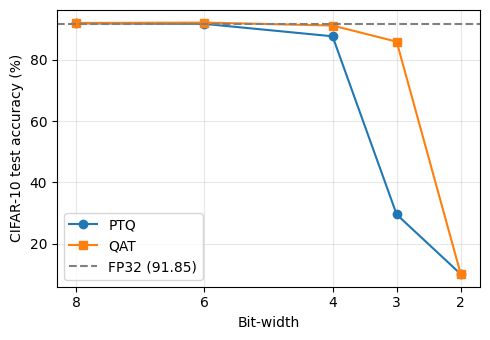

In [31]:
import matplotlib.pyplot as plt
bits    = [8, 6, 4, 3, 2]
ptq_acc = [91.91, 91.75, 87.69, 29.49, 10.0]
qat_acc = [92.04, 92.17, 91.21, 85.94, 10.0]
plt.figure(figsize=(5, 3.5))
plt.plot(bits, ptq_acc, 'o-', label='PTQ')
plt.plot(bits, qat_acc, 's-', label='QAT')
plt.axhline(91.85, ls='--', color='gray', label='FP32 (91.85)')
plt.xlabel('Bit-width'); plt.ylabel('CIFAR-10 test accuracy (%)')
plt.xticks(bits); plt.gca().invert_xaxis()
plt.legend(); plt.grid(alpha=.3); plt.tight_layout()
plt.savefig('bits_vs_acc.png', dpi=200)